# Which tetrahedron shapes carry the PV signal?

**Compare the catalogue helicity difference in fine bins of $r$ and $Q$.**
50 Gaussian initial conditions (seeds 1000–1049), displacement strength $A=16\ h^{-1}\mathrm{Mpc}$,
$L=1000\ h^{-1}\mathrm{Mpc}$ and field mesh $256^3$.
Each row uses the same fields with 32,768, 16,384 or 8,192 particles; random subsets are matched between helicities.
The ensemble includes the original ten shape-study realizations and 40 additional realizations from the saved confirmation run. This combined comparison remains exploratory.


## 1. Catalogue signal and uncertainty

Vertices are ordered by increasing sums of squared distances to the other vertices; vectors $\mathbf v_1,\mathbf v_2,\mathbf v_3$ start at the first vertex. The tetrahedron chirality is
$$\widehat\chi=\frac{\mathbf v_1\cdot(\mathbf v_2\times\mathbf v_3)}{|\mathbf v_1||\mathbf v_2||\mathbf v_3|}.$$
Exact ordering ties have $\widehat\chi=0$.

For shape bin $B$ and realization $s$,
$$S_{s,B}(\epsilon)=\frac{1}{N_{s,B}(\epsilon)}\sum_{t\in B}\widehat\chi_t(\epsilon),\qquad
D_{s,B}=S_{s,B}(+1)-S_{s,B}(-1),\qquad
\overline D_B=\frac1{n_B}\sum_{s\in\mathcal C_B}D_{s,B}.$$
$\epsilon=+1,-1$ denotes the two helicities; $N_{s,B}$ counts selected tetrahedra.
$\mathcal C_B$ contains the realizations with at least one tetrahedron in bin $B$ for **both helicities**, and $n_B=|\mathcal C_B|$ is their count (up to 50). **Each bar height is $\overline D_B$**. Each complete pair has equal weight; incomplete pairs are omitted from that bin. A negative bar means the positive-helicity catalogue has a lower mean chirality there.

Bins have width **0.02**, include their lower edge and exclude their upper edge (the last bin includes 1).
Error bars show one **standard error of the mean (SEM)** over those same complete pairs: $\mathrm{std}_{s\in\mathcal C_B}(D_{s,B},\mathrm{ddof}=1)/\sqrt{n_B}$.
Small numbers above bins give $n_B$ where it is below 50; unlabelled bars use all 50 pairs. Hatching means $n_B=0$; a single pair is shown without an SEM. Small populations can give noisy bars; per-bin counts are saved with the results.


In [1]:
from pathlib import Path
import json, sys
from IPython.display import display, Markdown
OUT = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/selection_geometry_20261122_50/fine_bins_available_pairs')
sys.path.insert(0, str(OUT/'code/src'))
from parity_study.tests.selection_bins import plot_response
from parity_study.storage import digest
report = json.loads((OUT/'analysis.json').read_text())
config = json.loads((OUT/'config.json').read_text())
assert report['complete'] and report['config_sha256'] == digest(OUT/'config.json')
%matplotlib inline
import matplotlib.pyplot as plt


## 2. Response in $r$ bins

$r=\ell_{\min}/\ell_{\max}$ is the ratio of the shortest to longest of the **three edges from the canonical reference vertex**. It is dimensionless and unchanged by reflection.

Gold shading marks the frozen selection $0.6905111410\le r<0.7567675935$. The three rows share both axes for direct comparison.

The first three populated bins in each row are hidden for readability; their measurements remain in the saved data.


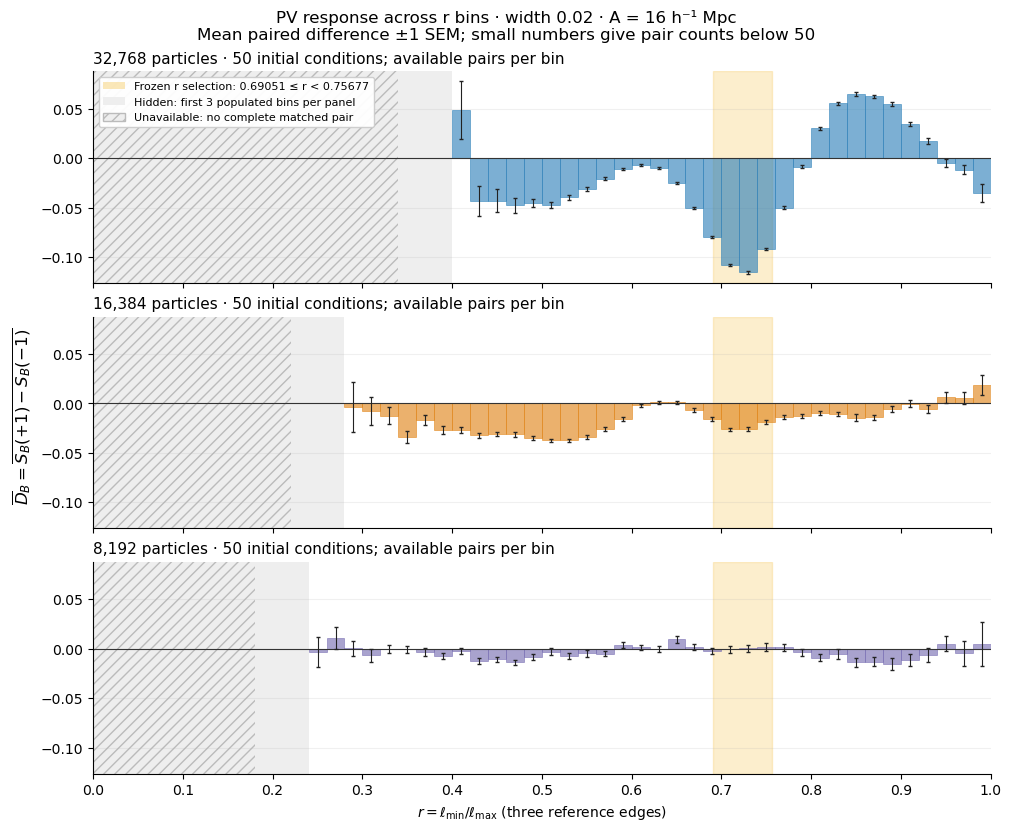

In [2]:
from pathlib import Path
import importlib.util
from IPython.display import display
import matplotlib.pyplot as plt
R_EDIT = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/selection_geometry_20261122_50/fine_bins_available_pairs/report_edits/r_omit_first_three')
spec = importlib.util.spec_from_file_location('pv_r_display', R_EDIT/'selection_bins.py')
r_display = importlib.util.module_from_spec(spec)
spec.loader.exec_module(r_display)
fig = r_display.plot_response(Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/selection_geometry_20261122_50/fine_bins_available_pairs'), 'r', omit_first_populated=3,
                              figure_dir=R_EDIT/'figures')
display(fig)
plt.close(fig)


## 3. Response in $Q$ bins

$Q=12(3V)^{2/3}/\sum_{i<j}\ell_{ij}^{2}$ uses the **volume $V$ and all six edges**. $Q=1$ is regular; $Q\to0$ is degenerate. It is dimensionless and unchanged by reflection.

Gold shading marks the **fiducial $Q$ selection, $0.4\le Q<0.8$**. Each bar applies only its own $Q$ interval; no $r$ cut is also imposed.


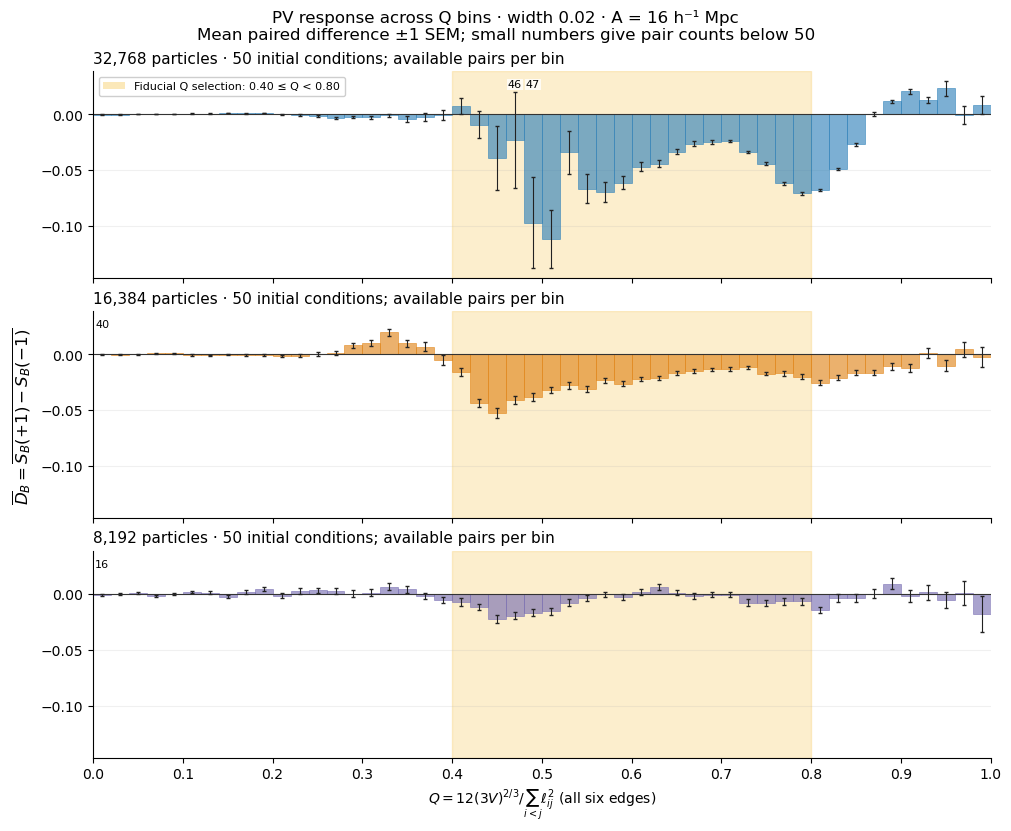

In [3]:
from pathlib import Path
import importlib.util
from IPython.display import display
import matplotlib.pyplot as plt
Q_EDIT = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/selection_geometry_20261122_50/fine_bins_available_pairs/report_edits/Q_fiducial_0p4_0p8')
spec = importlib.util.spec_from_file_location('pv_Q_fiducial_display', Q_EDIT/'selection_bins.py')
q_display = importlib.util.module_from_spec(spec)
spec.loader.exec_module(q_display)
fig = q_display.plot_response(Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/selection_geometry_20261122_50/fine_bins_available_pairs'), 'Q',
                              highlight=q_display.FIDUCIAL_Q_CUT,
                              figure_dir=Q_EDIT/'figures')
display(fig)
plt.close(fig)


## 4. Does the wider $0.4\le Q<0.8$ selection help?

Compare the new interval with $0.4\le Q<0.6$, the frozen $r$ cut, and all tetrahedra, using the same 50 realizations. The wider cut combines the chirality sums and tetrahedron counts of the two adjacent intervals **within each catalogue**, before calculating $D_s$.

Counts and retained fractions below average over the two helicity catalogues. The sensitivity measure is $|\overline{D}|/\mathrm{SEM}$: a larger value means a larger mean signal relative to its uncertainty in this ensemble.


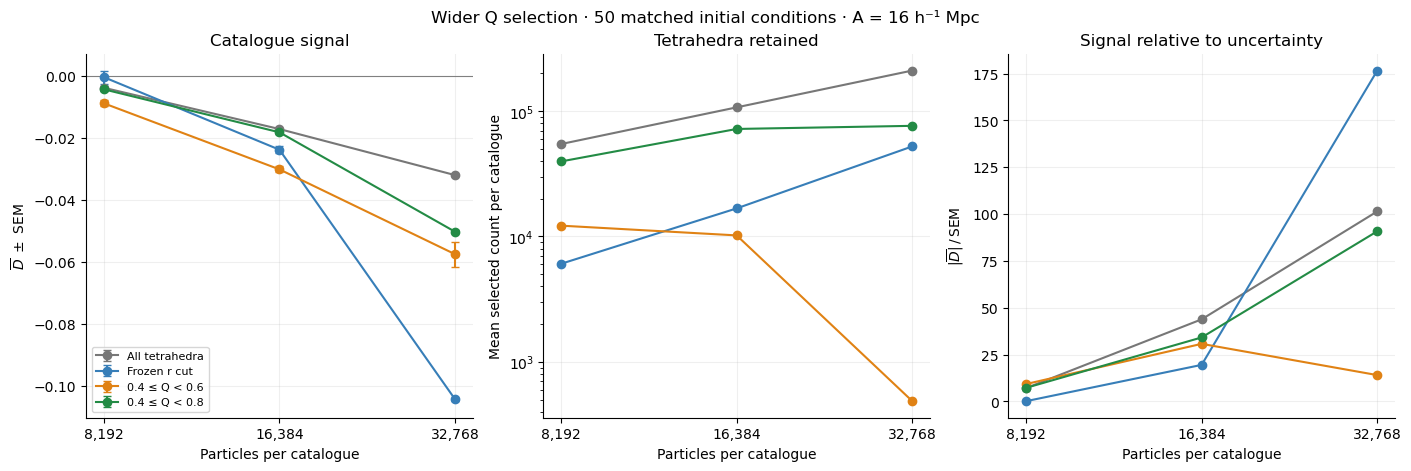

| Selection | Particles | Pairs | Mean tetrahedra | Retained | Mean D ± SEM | Signal / SEM |
|---|---:|---:|---:|---:|---:|---:|
| All tetrahedra | 32,768 | 50 | 210,704 | 100.00% | -0.03192 ± 0.00031 | 101.5 |
| Frozen r cut | 32,768 | 50 | 52,322 | 24.83% | -0.10421 ± 0.00059 | 176.7 |
| 0.4 ≤ Q < 0.6 | 32,768 | 50 | 485 | 0.23% | -0.05742 ± 0.00408 | 14.1 |
| 0.4 ≤ Q < 0.8 | 32,768 | 50 | 76,305 | 36.21% | -0.05018 ± 0.00055 | 90.9 |
| All tetrahedra | 16,384 | 50 | 107,147 | 100.00% | -0.01707 ± 0.00039 | 43.9 |
| Frozen r cut | 16,384 | 50 | 16,751 | 15.63% | -0.02373 ± 0.00121 | 19.5 |
| 0.4 ≤ Q < 0.6 | 16,384 | 50 | 10,197 | 9.52% | -0.03006 ± 0.00098 | 30.8 |
| 0.4 ≤ Q < 0.8 | 16,384 | 50 | 72,044 | 67.24% | -0.01811 ± 0.00053 | 34.2 |
| All tetrahedra | 8,192 | 50 | 54,598 | 100.00% | -0.00375 ± 0.00053 | 7.1 |
| Frozen r cut | 8,192 | 50 | 6,053 | 11.09% | -0.00033 ± 0.00213 | 0.2 |
| 0.4 ≤ Q < 0.6 | 8,192 | 50 | 12,197 | 22.34% | -0.00875 ± 0.00094 | 9.3 |
| 0.4 ≤ Q < 0.8 | 8,192 | 50 | 39,673 | 72.66% | -0.00425 ± 0.00059 | 7.3 |

**Wider Q interval compared with 0.4 ≤ Q < 0.6:**

- **32,768 particles:** 157.26× as many tetrahedra; 6.45× the signal-to-SEM ratio.
- **16,384 particles:** 7.07× as many tetrahedra; 1.11× the signal-to-SEM ratio.
- **8,192 particles:** 3.25× as many tetrahedra; 0.78× the signal-to-SEM ratio.

In [4]:
from pathlib import Path
import importlib.util, json, sys
from IPython.display import display, Markdown
COMPARE = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/selection_geometry_20261122_50/Q_wide_comparison')
sys.path.insert(0, str(COMPARE/'code/src'))
spec = importlib.util.spec_from_file_location('pv_selection_comparison', COMPARE/'code/src/parity_study/tests/selection_comparison.py')
comparison = importlib.util.module_from_spec(spec)
spec.loader.exec_module(comparison)
%matplotlib inline
import matplotlib.pyplot as plt
fig = comparison.figure(COMPARE)
display(fig)
plt.close(fig)
display(Markdown(comparison.summary_markdown(COMPARE)))


The wider $Q$ cut improves sensitivity at 32,768 and 16,384 particles. At 8,192 particles, it retains more tetrahedra but dilutes the mean signal enough to reduce sensitivity. The frozen $r$ cut still gives the highest sensitivity at the fiducial 32,768 particles.

The $0.4\le Q<0.8$ interval is adopted as the fiducial $Q$ selection. It was chosen after viewing these data, so this comparison remains exploratory. The frozen $r$ cut remains the $r$-based reference.


[Fine-bin data and counts](saved/selection_geometry_20261122_50/fine_bins_available_pairs/summary.csv) · [Per-realization arrays](saved/selection_geometry_20261122_50/fine_bins_available_pairs/catalogue_bins.npz) · [Plots](saved/selection_geometry_20261122_50/fine_bins_available_pairs/figures/) · [Configuration](saved/selection_geometry_20261122_50/fine_bins_available_pairs/config.json)


[Selection comparison data](saved/selection_geometry_20261122_50/Q_wide_comparison/summary.csv) · [Per-catalogue signals](saved/selection_geometry_20261122_50/Q_wide_comparison/catalogue_signals.csv) · [Comparison plot](saved/selection_geometry_20261122_50/Q_wide_comparison/figures/) · [Comparison configuration](saved/selection_geometry_20261122_50/Q_wide_comparison/config.json)

[r plot with first three populated bins hidden](saved/selection_geometry_20261122_50/fine_bins_available_pairs/report_edits/r_omit_first_three/figures/)

[Fiducial Q plot](saved/selection_geometry_20261122_50/fine_bins_available_pairs/report_edits/Q_fiducial_0p4_0p8/figures/)